In [1]:
import os
import json
import re
import requests
import pandas as pd
import numpy as np
from pathlib import Path
from transformers import AutoModelForCausalLM, AutoTokenizer
from types import SimpleNamespace

In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import cross_val_predict

In [3]:
start_dir = Path.cwd().resolve()
CSV_PATH = next(
    (
        folder / "data" / "processed" / "FINAL_newsprism_corpus.csv"
        for folder in (start_dir, *start_dir.parents)
        if (folder / "data" / "processed" / "FINAL_newsprism_corpus.csv").is_file()
    ),
    None,
)

if CSV_PATH is None:
    raise FileNotFoundError(
        f"Could not find FINAL_newsprism_corpus.csv from {start_dir} or its parent folders."
    )

df = pd.read_csv(CSV_PATH)
print(f"Loaded corpus from: {CSV_PATH}")

Loaded corpus from: D:\S1Y2 UTS\ANLP\ASSIGNMETNS\2\data\processed\FINAL_newsprism_corpus.csv


In [4]:
df.head()

,article_id,event_id,topic,title,publisher,domain,url,published_at,language,source_country,raw_text,clean_text,word_count
0,ART_68BA904019A2,IMM_014,immigration,7NEWS Spotlight: Pauline Hanson’s UK tour and ...,7NEWS,7news.com.au,https://7news.com.au/spotlight/7news-spotlight...,2026-07-19T07:00:00Z,English,Australia,Pauline Hanson has rarely had a better opportu...,Pauline Hanson has rarely had a better opportu...,950
1,ART_041B7EA0CFF0,IMM_008,immigration,Australian man dies in immigration detention i...,7NEWS,7news.com.au,https://7news.com.au/news/australian-man-dies-...,2026-07-11T07:00:00Z,English,Australia,An Australian man has died in while in immigra...,An Australian man has died in while in immigra...,354
2,ART_21098433ADD2,IMM_004,immigration,Amanda Rishworth and Nat Barr clash over tradi...,7NEWS,7news.com.au,https://7news.com.au/sunrise/amanda-rishworth-...,2026-07-07T07:00:00Z,English,Australia,Employment Minister Amanda Rishworth has refus...,Employment Minister Amanda Rishworth has refus...,510
3,ART_C6E51BFB5116,IMM_007,immigration,Pauline Hanson meets with UK far-right figure ...,7NEWS,7news.com.au,https://7news.com.au/news/pauline-hanson-meets...,2026-07-09T07:00:00Z,English,Australia,Pauline Hanson has met with UK far-right figur...,Pauline Hanson has met with UK far-right figur...,338
4,ART_C956A4AFDAC0,IMM_025,immigration,The Issue Podcast: Demographer says the tax sy...,7NEWS,7news.com.au,https://7news.com.au/news/the-issue-podcast-de...,2026-08-08T07:00:00Z,English,Australia,Leading demographer Professor Peter McDonald s...,Leading demographer Professor Peter McDonald s...,931


# 1. Distant supervision: add weak label.
Source: https://mediabiasfactcheck.com

In [5]:
OUTLET_SCORE = {
    "The Guardian Australia": -3.5, # no scoring found on australian guardian, however they share the same political leaning as the UK guardian
    "The Age": -4.0,
    "ABC News": -2.8,
    "Sydney Morning Herald": -2.3,
    "7NEWS": -1.7,
    "news.com.au": 2.8,
    "SBS News": -3.4
}

df["outlet_score"] = df["publisher"].map(OUTLET_SCORE)

In [6]:
def score_to_lean(score):
    if pd.isna(score):
        return None
    elif score <= -8.0:
        return "extreme-left"
    elif score <= -5.0:
        return "left"
    elif score <= -2.0:
        return "left-centre"
    elif score < 2.0:
        return "centre"
    elif score < 5.0:
        return "right-centre"
    elif score < 8.0:
        return "right"
    else:
        return "extreme-right"

df["outlet_lean"] = df["outlet_score"].apply(score_to_lean)

In [7]:
df.head()

,article_id,event_id,topic,title,publisher,domain,url,published_at,language,source_country,raw_text,clean_text,word_count,outlet_score,outlet_lean
0,ART_68BA904019A2,IMM_014,immigration,7NEWS Spotlight: Pauline Hanson’s UK tour and ...,7NEWS,7news.com.au,https://7news.com.au/spotlight/7news-spotlight...,2026-07-19T07:00:00Z,English,Australia,Pauline Hanson has rarely had a better opportu...,Pauline Hanson has rarely had a better opportu...,950,-1.7,centre
1,ART_041B7EA0CFF0,IMM_008,immigration,Australian man dies in immigration detention i...,7NEWS,7news.com.au,https://7news.com.au/news/australian-man-dies-...,2026-07-11T07:00:00Z,English,Australia,An Australian man has died in while in immigra...,An Australian man has died in while in immigra...,354,-1.7,centre
2,ART_21098433ADD2,IMM_004,immigration,Amanda Rishworth and Nat Barr clash over tradi...,7NEWS,7news.com.au,https://7news.com.au/sunrise/amanda-rishworth-...,2026-07-07T07:00:00Z,English,Australia,Employment Minister Amanda Rishworth has refus...,Employment Minister Amanda Rishworth has refus...,510,-1.7,centre
3,ART_C6E51BFB5116,IMM_007,immigration,Pauline Hanson meets with UK far-right figure ...,7NEWS,7news.com.au,https://7news.com.au/news/pauline-hanson-meets...,2026-07-09T07:00:00Z,English,Australia,Pauline Hanson has met with UK far-right figur...,Pauline Hanson has met with UK far-right figur...,338,-1.7,centre
4,ART_C956A4AFDAC0,IMM_025,immigration,The Issue Podcast: Demographer says the tax sy...,7NEWS,7news.com.au,https://7news.com.au/news/the-issue-podcast-de...,2026-08-08T07:00:00Z,English,Australia,Leading demographer Professor Peter McDonald s...,Leading demographer Professor Peter McDonald s...,931,-1.7,centre


# 2. LLM Silver label

In [8]:
import json
from typing import Literal

from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv()

OLLAMA_URL = "http://localhost:11434/api/chat"
MODEL_NAME = "gpt-oss"

INPUT_FILE = df
OUTPUT_FILE = Path("labeling_output/gpt_oss_labels.jsonl")

OUTPUT_FILE.parent.mkdir(exist_ok=True)

In [9]:
class PoliticalLeanLabel(BaseModel):
    label: Literal["left", "left-centre", "centre", "right-centre", "right"]

    confidence: float = Field(
        ge=0.0,
        le=1.0,
        description="Confidence in the political leaning classification."
    )

    rationale: str = Field(description="One concise sentence explaining the classification.")

In [10]:
def label_article(title, text, max_chars=8000):

    title = "" if pd.isna(title) else str(title)
    text = "" if pd.isna(text) else str(text)

    text = text[:max_chars]

    if not text.strip():
        return {
            "label": None,
            "confidence": 0.0,
            "rationale": "Empty article text."
        }
    
    prompt = f"""
        You are labelling the political leaning or framing of a news article.

        Classify the ARTICLE itself, not the political reputation of the publisher.

        Political leaning should be inferred from:
        - how political actors and policies are presented
        - which arguments or perspectives are emphasised
        - evaluative language
        - framing of political or social issues
        - treatment of competing viewpoints

        Do NOT infer political leaning from the publisher.

        Do NOT classify an article as centre simply because its writing style is factual or neutral. Centre means the article's framing does not clearly favour either left-leaning or right-leaning political positions.

        Return:
        - label: left, centre, or right
        - confidence: number between 0 and 1
        - rationale: one concise sentence

        Article title:
        {title}

        Article text:
        {text}
        """

    response = requests.post(
    OLLAMA_URL,
    json={
        "model": MODEL_NAME,
        "messages": [
            {
                "role": "user",
                "content": prompt
            }
        ],
        "stream": False,

        # GPT-OSS supports low / medium / high
        "think": "low",

        # Force JSON structure
        "format": {
            "type": "object",
            "properties": {
                "label": {
                    "type": "string",
                    "enum": [
                        "extreme-left",
                        "left",
                        "left-centre",
                        "centre",
                        "right-centre",
                        "right",
                        "extreme-right"
                    ]
                },
                "confidence": {
                    "type": "number",
                    "minimum": 0,
                    "maximum": 1
                },
                "rationale": {"type": "string"}
            },
            "required": ["label", "confidence", "rationale"]
        },

        "options": {"temperature": 0, "num_predict": 300}
    },
    timeout=300
)

    response.raise_for_status()

    raw = response.json()["message"]["content"].strip()

    try:
        result = json.loads(raw)

        return {
            "label": result["label"],
            "confidence": float(result["confidence"]),
            "rationale": result["rationale"]
        }

    except (json.JSONDecodeError, KeyError, ValueError) as e:
        return {
            "label": None,
            "confidence": 0.0,
            "rationale": f"Parse error: {raw[:200]}"
        }

    # match = re.search(r"\{.*\}", raw, re.DOTALL)

    # if not match:
    #     return {
    #         "label": None,
    #         "confidence": 0.0,
    #         "rationale": f"Parse error: {raw[:200]}"
    #     }

In [11]:
import time
# load already labeled articles if the output file exists
if OUTPUT_FILE.exists():
    existing = pd.read_json(OUTPUT_FILE, lines=True)
    done_ids = set(existing["article_id"])
else:
    done_ids = set()

for i, row in df.iterrows():

    article_id = row["article_id"]

    if article_id in done_ids:
        continue

    start = time.time()

    result = label_article(title=row["title"], text=row["clean_text"])

    result["article_id"] = article_id

    # Save immediately
    with open(OUTPUT_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(result, ensure_ascii=False) + "\n")

    elapsed = time.time() - start

    print(
        f"{i + 1}/{len(df)} | "
        f"{result['label']} | "
        f"{result['confidence']:.2f} | "
        f"{elapsed:.1f}s"
    )

# 3. Compare the weak labellers

In [12]:
gpt_labels = pd.read_json(OUTPUT_FILE, lines=True)

gpt_labels = gpt_labels.rename(
    columns={
        "label": "label_gpt_oss",
        "confidence": "gpt_oss_confidence",
        "rationale": "gpt_oss_rationale"
    }
)

df_compare = df.merge(gpt_labels[["article_id", "label_gpt_oss", "gpt_oss_confidence", "gpt_oss_rationale"]], on="article_id", how="left")

In [13]:
df_compare[["article_id", "publisher", "outlet_lean", "label_gpt_oss", "gpt_oss_confidence"]].head()

,article_id,publisher,outlet_lean,label_gpt_oss,gpt_oss_confidence
0,ART_68BA904019A2,7NEWS,centre,left,0.92
1,ART_041B7EA0CFF0,7NEWS,centre,centre,0.92
2,ART_21098433ADD2,7NEWS,centre,right,0.92
3,ART_C6E51BFB5116,7NEWS,centre,right,0.92
4,ART_C956A4AFDAC0,7NEWS,centre,centre,0.60


In [14]:
def lean_to_direction(label):
    if pd.isna(label):
        return None

    if label in ["extreme-left", "left", "left-centre"]:
        return "left"

    if label == "centre":
        return "centre"

    if label in ["right-centre", "right", "extreme-right"]:
        return "right"

    return None

In [15]:
df_compare["outlet_direction"] = (df_compare["outlet_lean"].apply(lean_to_direction))
df_compare["gpt_oss_direction"] = (df_compare["label_gpt_oss"].apply(lean_to_direction))

In [16]:
df_compare["weak_label_agreement"] = (df_compare["outlet_direction"] == df_compare["gpt_oss_direction"])

In [17]:
# cohen's kappa score to measure agreement between outlet and GPT-OSS labels
from sklearn.metrics import cohen_kappa_score

valid = df_compare.dropna(subset=["outlet_direction","gpt_oss_direction"])
kappa = cohen_kappa_score(valid["outlet_direction"],valid["gpt_oss_direction"])

print(f"Cohen's kappa: {kappa:.3f}")

Cohen's kappa: 0.080


In [18]:
disagreements = df_compare[~df_compare["weak_label_agreement"]]
disagreements.head()

,article_id,event_id,topic,title,publisher,domain,url,published_at,language,source_country,...,clean_text,word_count,outlet_score,outlet_lean,label_gpt_oss,gpt_oss_confidence,gpt_oss_rationale,outlet_direction,gpt_oss_direction,weak_label_agreement
0,ART_68BA904019A2,IMM_014,immigration,7NEWS Spotlight: Pauline Hanson’s UK tour and ...,7NEWS,7news.com.au,https://7news.com.au/spotlight/7news-spotlight...,2026-07-19T07:00:00Z,English,Australia,...,Pauline Hanson has rarely had a better opportu...,950,-1.7,centre,left,0.92,The article aggressively critiques Pauline Han...,centre,left,False
2,ART_21098433ADD2,IMM_004,immigration,Amanda Rishworth and Nat Barr clash over tradi...,7NEWS,7news.com.au,https://7news.com.au/sunrise/amanda-rishworth-...,2026-07-07T07:00:00Z,English,Australia,...,Employment Minister Amanda Rishworth has refus...,510,-1.7,centre,right,0.92,The article frames the issue as a right‑leanin...,centre,right,False
3,ART_C6E51BFB5116,IMM_007,immigration,Pauline Hanson meets with UK far-right figure ...,7NEWS,7news.com.au,https://7news.com.au/news/pauline-hanson-meets...,2026-07-09T07:00:00Z,English,Australia,...,Pauline Hanson has met with UK far-right figur...,338,-1.7,centre,right,0.92,The article frames far‑right figures and anti‑...,centre,right,False
5,ART_8331F403212C,IMM_062,immigration,WA’s multibillion-dollar grain harvest at risk...,7NEWS,7news.com.au,https://7news.com.au/news/was-multibillion-dol...,2026-09-28T13:07:00Z,English,Australia,...,There are fears a bumper multibillion-dollar h...,345,-1.7,centre,right,0.92,The article portrays the federal visa crackdow...,centre,right,False
8,ART_63F7E2634B51,IMM_001,immigration,"Military called in as more than 40,000 migrant...",ABC News,abc.net.au,https://www.abc.net.au/news/2026-07-31/spain-m...,2026-07-30T07:00:00Z,English,Australia,...,"In short: Spanish officials say more than 40,0...",869,-2.8,left-centre,centre,0.60,The article presents both the Spanish governme...,left,centre,False


In [19]:
disagreements.to_csv("labeling_output/disagreements.csv", index=False)

In [20]:
disagreements.info()

<class 'pandas.DataFrame'>
Index: 105 entries, 0 to 249
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   article_id            105 non-null    str    
 1   event_id              105 non-null    str    
 2   topic                 105 non-null    str    
 3   title                 105 non-null    str    
 4   publisher             105 non-null    str    
 5   domain                105 non-null    str    
 6   url                   105 non-null    str    
 7   published_at          105 non-null    str    
 8   language              105 non-null    str    
 9   source_country        105 non-null    str    
 10  raw_text              105 non-null    str    
 11  clean_text            105 non-null    str    
 12  word_count            105 non-null    int64  
 13  outlet_score          86 non-null     float64
 14  outlet_lean           86 non-null     str    
 15  label_gpt_oss         104 non-null    s

# 5. Select articles for human annotation & Read human labels back

In [21]:
agree = df_compare[df_compare["weak_label_agreement"]].sample(n=min(20, df_compare["weak_label_agreement"].sum()),random_state=42)
disagree = df_compare[~df_compare["weak_label_agreement"]].sample(n=min(40, (~df_compare["weak_label_agreement"]).sum()),random_state=42)
human_sample = pd.concat([agree, disagree]).sample(frac=1, random_state=42)

In [22]:
import openpyxl
HUMAN_PATH = "D:/S1Y2 UTS/ANLP/ASSIGNMETNS/2/notebooks/02_political_leaning/labeling_output/human_annotation_standardised (1).xlsx"
human = pd.read_excel(HUMAN_PATH)

In [23]:
human = human.rename(columns={"annotation_2": "label_human_5class"})
human["label_human_5class"] = (human["label_human_5class"].astype("string").str.strip())

human[["article_id", "label_human_5class"]].head()

,article_id,label_human_5class
0,ART_68BA904019A2,Left-centre
1,ART_041B7EA0CFF0,Centre
2,ART_21098433ADD2,Centre
3,ART_C6E51BFB5116,Right-centre
4,ART_C956A4AFDAC0,Centre


# 6. Evaluate the outlet labels against humans

In [24]:
human_map = {
    "Left": "left",
    "Left-centre": "left",
    "Centre": "centre",
    "Right-centre": "right",
    "Right": "right"
}

human["label_human"] = human["label_human_5class"].map(human_map)

In [25]:
human["label_human"].value_counts(dropna=False)

label_human
left      141
centre     85
right      27
Name: count, dtype: int64

# 7. TD-IDF/Logistic Regression baseline

In [26]:
model_data = human[human["label_human"].isin(["left", "centre", "right"])].copy()

In [27]:
X_train, X_test, y_train, y_test = train_test_split(model_data["clean_text"], model_data["label_human"], test_size=0.25, random_state=42, stratify=model_data["label_human"])

In [28]:
tfidf_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])

In [29]:
tfidf_model.fit(X_train, y_train)
y_pred = tfidf_model.predict(X_test)

In [30]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

      centre       0.44      0.38      0.41        21
        left       0.58      0.69      0.63        36
       right       0.00      0.00      0.00         7

    accuracy                           0.52        64
   macro avg       0.34      0.36      0.35        64
weighted avg       0.47      0.52      0.49        64



In [31]:
# inspect what tfidf learned

vectorizer = tfidf_model.named_steps["tfidf"]
classifier = tfidf_model.named_steps["classifier"]

features = np.array(
    vectorizer.get_feature_names_out()
)

for i, label in enumerate(classifier.classes_):
    top = np.argsort(
        classifier.coef_[i]
    )[-15:]

    print(f"\n{label.upper()}")
    print(features[top])


CENTRE
['prices' 'cent' 'buyers' 'mortgage' 'price' 'darwin' 'police' 'the us'
 'interest' 'phillips' 'us' 'farley' 'house' 'india' 'vanguard']

LEFT
['we' 'report' 'grid' 'gas' 'carbon' 'by' 'emissions' 'power' 'in'
 'panels' 'solar' 'wind' 'coal' 'climate' 'energy']

RIGHT
['tax' 'rate' 'correction' 'clearance' 'overseas' 'the' 'capital'
 'robinson' 'australiaâ' 'temporary' 'sheâ' 'migration' 'students'
 'airport' 'visa']


NOTE: terms are assoiated with the classifier's predictions, not inherently left or right wing terms.

# 8. Train using silver labels

## 8.1. Tf-IDF -> Logistic

In [32]:
df_model = df.merge(gpt_labels, on="article_id", how="left")
df_model = df_model[df_model["label_gpt_oss"].notna()]

In [33]:
silver = df_model[(df_model["gpt_oss_confidence"] >= 0.75) & df_model["label_gpt_oss"].isin(["left", "centre", "right"])].copy()

In [34]:
tfidf_silver_logreg = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.90, stop_words="english", sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

tfidf_silver_logreg.fit(silver["clean_text"], silver["label_gpt_oss"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['centre','left','right']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.9
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by ter

In [35]:
# performance evaluated on 5 fold cv
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

In [36]:
lr_scores = cross_validate(tfidf_silver_logreg, silver["clean_text"], silver["label_gpt_oss"], cv=cv, scoring=scoring)

lr_pred = cross_val_predict(tfidf_silver_logreg, silver["clean_text"], silver["label_gpt_oss"], cv=cv)

In [37]:
print("Logistic Regression")
print(classification_report(silver["label_gpt_oss"], lr_pred, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

      centre       0.74      0.42      0.54        33
        left       0.78      0.96      0.86       132
       right       0.50      0.10      0.16        21

    accuracy                           0.77       186
   macro avg       0.67      0.49      0.52       186
weighted avg       0.74      0.77      0.72       186



In [38]:
print(
    "TF-IDF LR Macro F1:", lr_scores["test_macro_f1"].mean(),
    "+/-", lr_scores["test_macro_f1"].std()
)

TF-IDF LR Macro F1: 0.4954107808584534 +/- 0.09146018580777547


NOTE: evaluate this against human labels

In [39]:
vectorizer = tfidf_silver_logreg.named_steps["tfidf"]
classifier = tfidf_silver_logreg.named_steps["classifier"]

features = np.array(vectorizer.get_feature_names_out())

for i, label in enumerate(classifier.classes_):
    top = np.argsort(classifier.coef_[i])[-15:]

    print(f"\n{label.upper()}")
    print(features[top])


CENTRE
['grants' 'tasmania' 'darwin' 'prices falling' 'price' 'iran' 'rates'
 'prices' 'market' 'reserve' 'cotality' 'battery' 'buyer' 'domain'
 'downturn']

LEFT
['net zero' 'action' 'governments' 'building' 'need' 'guardian' 'fuels'
 'electricity' 'public' 'climate change' 'spokesperson' 'gas' 'coal'
 'fossil' 'climate']

RIGHT
['datacentres' 'backpackers' 'nightmare' 'visa' 'boats' 'train' 'negative'
 'migration' 'ai' 'labor' 'related' 'plan' 'farmers' 'skilled' 'nation']


Insights of the highest-weighted TF-IDF features: 

* Classifier captured both potentially ideological language and topic-specific associations. For example, climate and energy terms were strongly associated with left-labelled articles, while migration and national-politics terms were associated with right-labelled articles. 

* Indicates possible topic-label confounding, where the classifier may partially learn which issues occur within each class rather than political framing alone.

## 8.2. Tf-IDF -> LinearSVM

In [40]:
from sklearn.svm import LinearSVC

tfidf_svm = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.90, stop_words="english", sublinear_tf=True)),
    ("classifier", LinearSVC(class_weight="balanced"))
])

In [41]:
tfidf_svm.fit(silver["clean_text"], silver["label_gpt_oss"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['centre','left','right']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.9
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by ter

In [42]:
svm_scores = cross_validate(tfidf_svm, silver["clean_text"], silver["label_gpt_oss"], cv=cv, scoring=scoring)
svm_pred = cross_val_predict(tfidf_svm, silver["clean_text"], silver["label_gpt_oss"], cv=cv)

In [43]:
print("LinearSVM")
print(classification_report(silver["label_gpt_oss"], svm_pred, zero_division=0))

LinearSVM
              precision    recall  f1-score   support

      centre       0.82      0.42      0.56        33
        left       0.78      0.99      0.87       132
       right       0.00      0.00      0.00        21

    accuracy                           0.78       186
   macro avg       0.53      0.47      0.48       186
weighted avg       0.70      0.78      0.72       186



In [44]:
vectorizer = tfidf_svm.named_steps["tfidf"]
classifier = tfidf_svm.named_steps["classifier"]

features = np.array(vectorizer.get_feature_names_out())

for i, label in enumerate(classifier.classes_):
    top = np.argsort(classifier.coef_[i])[-15:]

    print(f"\n{label.upper()}")
    print(features[top])


CENTRE
['million' 'expectations' 'ahead' 'prices falling' 'rates' 'darwin'
 'tasmania' 'iran' 'buyer' 'good energy' 'grants' 'reserve' 'battery'
 'downturn' 'domain']

LEFT
['gas' 'law' 'case' 'climate change' 'fuels' 'said' 'coal' 'need'
 'guardian' 'governments' 'public' 'building' 'spokesperson' 'fossil'
 'climate']

RIGHT
['backpackers' 'government plans' 'dollar' 'duniam' 'boats' 'nightmare'
 'labor' 'nation' 'train' 'ai' 'negative' 'skilled' 'farmers' 'plan'
 'related']


In [45]:
results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "TF-IDF + Linear SVM"
    ],

    "Accuracy": [
        lr_scores["test_accuracy"].mean(),
        svm_scores["test_accuracy"].mean()
    ],

    "Macro F1": [
        lr_scores["test_macro_f1"].mean(),
        svm_scores["test_macro_f1"].mean()
    ],

    "Macro F1 SD": [
        lr_scores["test_macro_f1"].std(),
        svm_scores["test_macro_f1"].std()
    ],
    
    "Weighted F1": [
        lr_scores["test_weighted_f1"].mean(),
        svm_scores["test_weighted_f1"].mean()
    ]
})

results.round(3)

,Model,Accuracy,Macro F1,Macro F1 SD,Weighted F1
0,TF-IDF + Logistic Regression,0.769,0.495,0.091,0.716
1,TF-IDF + Linear SVM,0.780,0.460,0.085,0.710


## 8.3. Silver-label Embedding models

In [46]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
X_embeddings = embedding_model.encode(df_model["clean_text"].fillna("").tolist(), normalize_embeddings=True)

y = df_model["label_gpt_oss"] # pick this as the target variable because gpt-oss labels are outlet-level, while distant supervision labels are article-level and may be less reliable

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X_embeddings, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [48]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

minilm_scores = cross_validate(model, X_embeddings, y, cv=cv, scoring=["f1_macro", "f1_weighted", "accuracy"])

print(classification_report(y_test, y_pred, zero_division=0))

print("Macro F1:", minilm_scores["test_f1_macro"].mean(),
      "+/-", minilm_scores["test_f1_macro"].std())

              precision    recall  f1-score   support

      centre       0.37      0.47      0.41        15
        left       0.67      0.52      0.58        31
       right       0.12      0.20      0.15         5

    accuracy                           0.47        51
   macro avg       0.39      0.39      0.38        51
weighted avg       0.53      0.47      0.49        51

Macro F1: 0.40369814180169755 +/- 0.03333302327269351


In [49]:
embedding_model = SentenceTransformer("all-mpnet-base-v2")
X_embeddings = embedding_model.encode(df_model["clean_text"].fillna("").tolist(), normalize_embeddings=True)

y = df_model["label_gpt_oss"] # pick this as the target variable because gpt-oss labels are article-level, while distant supervision labels are outlet-level and may be less reliable

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

* Trial 1: use MiniLM for embedding which is a relatively generic framework

* Trial 2: chunk text instead of feed the embedding the whole article which could truncate the article and possible information + switch to mpnet

In [50]:
def chunk_text(text, chunk_size=200):
    words = str(text).split()
    return [" ".join(words[i:i + chunk_size]) for i in range(0, len(words), chunk_size)]

In [51]:
def embed_article(text):
    chunks = chunk_text(text)

    if not chunks:
        return np.zeros(embedding_model.get_embedding_dimension())

    chunk_embeddings = embedding_model.encode(chunks, normalize_embeddings=True)
    article_embedding = chunk_embeddings.mean(axis=0)

    # Normalise again after averaging
    article_embedding /= np.linalg.norm(article_embedding)

    return article_embedding

In [52]:
# generate all article embeddings 
X_embeddings = np.vstack(df_model["clean_text"].fillna("").apply(embed_article))

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X_embeddings, y, test_size=0.2, random_state=42, stratify=y)

embed_chunk_model = LogisticRegression(max_iter=2000, class_weight="balanced")
embed_chunk_model.fit(X_train, y_train)

y_pred = embed_chunk_model.predict(X_test)

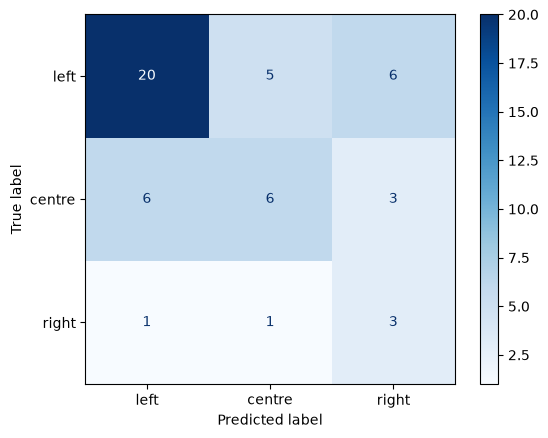

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["left", "centre", "right"], cmap="Blues")

plt.show()

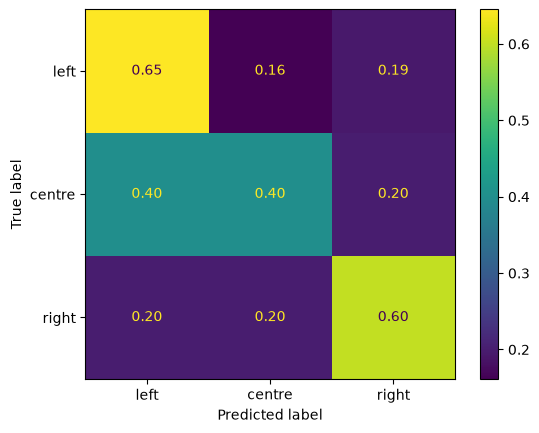

In [55]:
# row-nornalised cm
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["left", "centre", "right"], normalize="true", values_format=".2f")

plt.show()

The normalised confusion matrix indicates moderate discrimination across all three classes, with recall of 0.61 for left, 0.47 for centre and 0.60 for right. Centre articles were most frequently misclassified as left (0.33), while 0.40 of right-labelled articles were incorrectly classified as left. Notably, no right-labelled articles were classified as centre. This suggests that the semantic embedding representation may not encode political orientation as a simple left–centre–right continuum and may instead be influenced by topical similarity between ideologically opposing articles.

In [56]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(model, X_embeddings, y, cv=cv, scoring=["f1_macro", "f1_weighted", "accuracy"])

print(classification_report(y_test, y_pred, zero_division=0))

print("Macro F1:", scores["test_f1_macro"].mean(),
      "+/-", scores["test_f1_macro"].std())

              precision    recall  f1-score   support

      centre       0.50      0.40      0.44        15
        left       0.74      0.65      0.69        31
       right       0.25      0.60      0.35         5

    accuracy                           0.57        51
   macro avg       0.50      0.55      0.50        51
weighted avg       0.62      0.57      0.58        51

Macro F1: 0.5144190724919226 +/- 0.08575482581664261


Using 5-fold stratified cross-validation, the classifier achieved a mean macro F1-score of 0.523 (SD = 0.104). The result was broadly consistent with the held-out test performance, although the relatively high variability across folds suggests sensitivity to the small and imbalanced dataset.

# 9. Train on gold-label

In [76]:
df_gold = df_model.merge(human[["article_id", "label_human_5class", "label_human"]], on="article_id", how="left")
df_gold[["article_id","label_gpt_oss","label_human_5class","label_human"]].head()

,article_id,label_gpt_oss,label_human_5class,label_human
0,ART_68BA904019A2,left,Left-centre,left
1,ART_041B7EA0CFF0,centre,Centre,centre
2,ART_21098433ADD2,right,Centre,centre
3,ART_C6E51BFB5116,right,Right-centre,right
4,ART_C956A4AFDAC0,centre,Centre,centre


In [77]:
comparison = df_gold[df_gold["label_human"].notna() & df_gold["label_gpt_oss"].notna()].copy()

print(
    classification_report(
        comparison["label_human"],
        comparison["label_gpt_oss"],
        labels=["left", "centre", "right"],
        zero_division=0
    )
)

print(
    "Cohen's kappa:",
    cohen_kappa_score(
        comparison["label_human"],
        comparison["label_gpt_oss"]
    )
)

              precision    recall  f1-score   support

        left       0.75      0.82      0.78       141
      centre       0.60      0.54      0.57        84
       right       0.30      0.26      0.28        27

    accuracy                           0.66       252
   macro avg       0.55      0.54      0.54       252
weighted avg       0.65      0.66      0.65       252

Cohen's kappa: 0.38570076572313516


Comparison between GPT-OSS silver labels and the human reference annotations produced an accuracy of 0.66, Macro F1 of 0.54, and Cohen's κ of 0.386, indicating only modest-to-moderate agreement. Agreement was substantially stronger for the left class than for the right class, suggesting that the LLM-generated labels should be treated as noisy silver supervision rather than a substitute for human annotation.

In [78]:
gold = df_gold[df_gold["label_human"].notna()].copy()
gold["label_human"].value_counts()

label_human
left      141
centre     84
right      27
Name: count, dtype: int64

In [79]:
X_gold = np.vstack([embed_article(text) for text in gold["clean_text"].fillna("")])

y_gold = gold["label_human"]

print(X_gold.shape)

(252, 768)


In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X_gold,
    y_gold,
    test_size=0.2,
    stratify=y_gold,
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

In [99]:
print(
    classification_report(
        y_test,
        pred,
        labels=["left", "centre", "right"],
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        pred,
        average="macro"
    )
)

              precision    recall  f1-score   support

        left       0.67      0.48      0.56        29
      centre       0.32      0.41      0.36        17
       right       0.00      0.00      0.00         5

    accuracy                           0.41        51
   macro avg       0.33      0.30      0.31        51
weighted avg       0.49      0.41      0.44        51

Macro F1: 0.3063247863247864


In [81]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
gold_model = LogisticRegression(max_iter=2000, class_weight="balanced")

# oof: each article is predicted by a model that didnt train on that article
oof_pred = cross_val_predict(gold_model, X_gold, y_gold, cv=cv)

print(
    classification_report(
        y_gold,
        oof_pred,
        labels=["left", "centre", "right"],
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        y_gold,
        oof_pred,
        average="macro"
    )
)

              precision    recall  f1-score   support

        left       0.79      0.67      0.72       141
      centre       0.62      0.52      0.57        84
       right       0.23      0.52      0.31        27

    accuracy                           0.60       252
   macro avg       0.55      0.57      0.54       252
weighted avg       0.67      0.60      0.63       252

Macro F1: 0.535141866711276


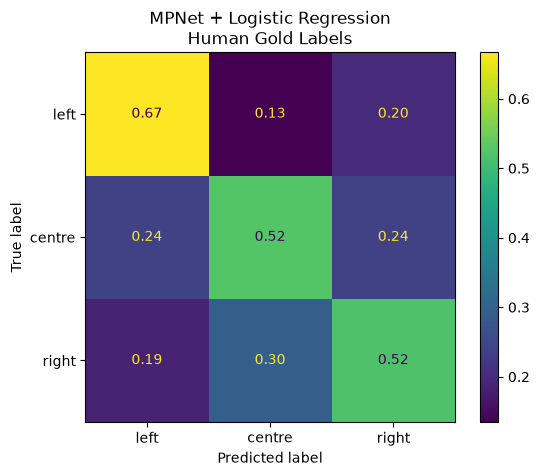

In [82]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_gold,
    oof_pred,
    labels=["left", "centre", "right"],
    normalize="true",
    values_format=".2f"
)

plt.title("MPNet + Logistic Regression\nHuman Gold Labels")
plt.show()

Using human annotations as the reference labels, the MPNet + Logistic Regression classifier achieved a Macro F1 of 0.535. Performance was strongest for left-leaning articles (F1 = 0.72), while centre and right remained more difficult to distinguish. Although the right class achieved 0.52 recall, its low precision (0.23) indicates substantial false-positive classification. These results reinforce earlier embedding-space analysis showing that pretrained semantic representations encode topical similarity more strongly than political orientation.

In [83]:
final_model = LogisticRegression(max_iter=2000, class_weight="balanced")

final_model.fit(X_gold, y_gold)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

## Create the final label

In [117]:
def collapse_lean(label):
    if pd.isna(label):
        return pd.NA

    label = str(label).strip().lower()

    if label in ["extreme-left", "left", "left-centre", "left-center"]:
        return "left"

    elif label in ["centre", "center", "least biased"]:
        return "centre"

    elif label in ["right-centre", "right-center", "right", "extreme-right"]:
        return "right"

    return pd.NA

def establish_reference_label(row):
    human = row["label_human"]

    machine_labels = [
        row["outlet_lean"],
        row["label_gpt_oss"]
    ]

    available = [
        label for label in machine_labels
        if pd.notna(label)
    ]

    agreement_count = sum(
        label == human
        for label in available
    )

    if len(available) == 2:
        if agreement_count == 2:
            support = "high"
        elif agreement_count == 1:
            support = "medium"
        else:
            support = "low"

    else:
        support = "insufficient"

    return pd.Series({
        "reference_label": human,
        "reference_support": support,
        "machine_agreement_count": agreement_count,
        "machine_labels_available": len(available)
    })

In [118]:
result = (
    df
    .merge(
        df_model[["article_id", "label_gpt_oss"]],
        on="article_id",
        how="left"
    )
    .merge(
        df_gold[["article_id", "label_human"]],
        on="article_id",
        how="left"
    )
)

In [119]:
result["outlet_lean"] = result["outlet_lean"].apply(collapse_lean)
result["label_gpt_oss"] = result["label_gpt_oss"].apply(collapse_lean)
result["label_human"] = result["label_human"].apply(collapse_lean)

In [ ]:
result[["reference_label", "reference_support", "machine_agreement_count", "machine_labels_available"
]] = result.apply(establish_reference_label, axis=1)

In [121]:
pd.crosstab(
    result["reference_support"],
    result["reference_label"]
)

reference_label,centre,left,right
reference_support,,,
high,5,108,0
insufficient,5,6,8
low,34,1,15
medium,40,26,4


In [ ]:
eval_df = result[result["reference_label"].notna()].copy().reset_index(drop=True)

In [134]:
eval_df["oof_prediction"] = oof_pred

In [ ]:
print(
    classification_report(
        eval_df["reference_label"],
        eval_df["oof_prediction"],
        labels=["left", "centre", "right"],
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        eval_df["reference_label"],
        eval_df["oof_prediction"],
        average="macro"
    )
)

              precision    recall  f1-score   support

        left       0.79      0.67      0.72       141
      centre       0.62      0.52      0.57        84
       right       0.23      0.52      0.31        27

    accuracy                           0.60       252
   macro avg       0.55      0.57      0.54       252
weighted avg       0.67      0.60      0.63       252

Macro F1: 0.535141866711276


In [138]:
for level in ["high", "medium", "low"]:
    subset = eval_df[
        eval_df["reference_support"] == level
    ]

    if len(subset) == 0:
        continue

    print(f"\n--- {level.upper()} SUPPORT ---")
    print("n =", len(subset))

    print(
        classification_report(
            subset["reference_label"],
            subset["oof_prediction"],
            labels=["left", "centre", "right"],
            zero_division=0
        )
    )


--- HIGH SUPPORT ---
n = 113
              precision    recall  f1-score   support

        left       1.00      0.72      0.84       108
      centre       0.17      0.40      0.24         5
       right       0.00      0.00      0.00         0

    accuracy                           0.71       113
   macro avg       0.39      0.37      0.36       113
weighted avg       0.96      0.71      0.81       113


--- MEDIUM SUPPORT ---
n = 70
              precision    recall  f1-score   support

        left       0.62      0.50      0.55        26
      centre       0.76      0.65      0.70        40
       right       0.07      0.25      0.11         4

    accuracy                           0.57        70
   macro avg       0.48      0.47      0.45        70
weighted avg       0.67      0.57      0.61        70


--- LOW SUPPORT ---
n = 50
              precision    recall  f1-score   support

        left       0.06      1.00      0.12         1
      centre       0.71      0.35      0

The human annotation remains the reference label. GPT-OSS article labels and MBFC outlet orientation are compared with the human label to quantify cross-signal agreement, rather than to determine the reference label or its correctness.

# 10. Does semantic representation improve political-leaning classification compared with lexical TF-IDF features?

TF-IDF + Logistics Regression model has higher confidence in detecting on the majority class but performance declines for minority class, whereas embedding Logistics model trade some majority-class performance for better minority class recall. Both models share roughly same Macro F1 score, hence the decision now is to use a model with strong majority-class discrimination at the expense of minority class or more even sensitivity across all political leaning classes. 

For NewsPrism prototype, balanced class performance is more valuable than higher majority-class accuracy, as failing to recognise one political orientation would undermine the purpose of comparing different perspectives. Hence the final model would be Logistic Regression with Embeddings.

# 11. What structure do the semantic embeddings capture in the NewsPrism corpus, and how does the classifier separate political-leaning classes within that space?

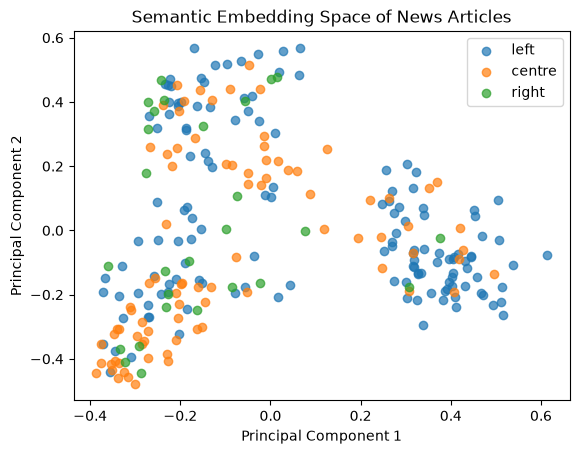

In [85]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X_gold)

plot_df = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "label": y_gold.values})

for label in ["left", "centre", "right"]:
    subset = plot_df[plot_df["label"] == label]

    plt.scatter(subset["PC1"], subset["PC2"], label=label, alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Semantic Embedding Space of News Articles")
plt.legend()
plt.show()

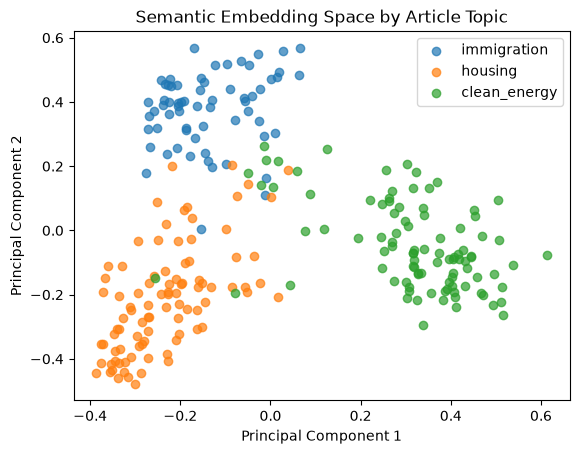

In [86]:
pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X_gold)

plot_df = pd.DataFrame({"PC1": X_2d[:, 0], "PC2": X_2d[:, 1], "topic": df_gold["topic"].values})

for topic in plot_df["topic"].dropna().unique():

    subset = plot_df[plot_df["topic"] == topic]

    plt.scatter(subset["PC1"], subset["PC2"], label=topic, alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Semantic Embedding Space by Article Topic")
plt.legend()
plt.show()

In [87]:
print("Variance explained:", pca.explained_variance_ratio_.sum())

Variance explained: 0.24817945


PCA projection of the semantic article embeddings shows several distinct regions within the corpus, indicating that the embedding model captures meaningful semantic variation between articles. However, the left, centre and right silver labels substantially overlap within these regions, with no visually distinct ideological clusters. This suggests that political leaning is not the dominant source of variation in the embedding space. The clusters may instead reflect underlying article topics, events or other semantic characteristics.

In contrast to political leaning, PCA projection by article topic produced clearly distinguishable clusters for immigration, housing, and clean energy. This suggests that the pretrained semantic embeddings encode topical similarity much more strongly than political orientation. The result is consistent with the way the NewsPrism corpus was constructed, with articles deliberately sampled across three predefined topics. Consequently, topic represents a major source of variation in the embedding space, while political leaning appears to be a subtler characteristic that cuts across these topic clusters. This helps explain why semantic embeddings did not produce clear separation between left-, centre-, and right-labelled articles: articles with opposing political framing may remain close in embedding space when they discuss the same underlying topic.

In [89]:
labels = np.array(y_gold)
centroids = {}

for label in ["left", "centre", "right"]:
    centroids[label] = X_embeddings[labels == label].mean(axis=0)

In [90]:
from sklearn.metrics.pairwise import cosine_similarity

centroid_matrix = np.vstack([ centroids["left"], centroids["centre"], centroids["right"]])
similarity = cosine_similarity(centroid_matrix)
similarity_df = pd.DataFrame( similarity, index=["left", "centre", "right"], columns=["left", "centre", "right"])

similarity_df

,left,centre,right
left,1.000000,0.925033,0.911675
centre,0.925033,1.000000,0.958107
right,0.911675,0.958107,1.000000


The class centroids for political leaning were highly similar in semantic embedding space, with pairwise cosine similarities between 0.917 and 0.943. This indicates that the average semantic representations of left-, centre-, and right-labelled articles are closely located, supporting the PCA observation that political orientation is not strongly separated by the pretrained embedding representation.

In [91]:
for label in ["left", "centre", "right"]:

    mask = labels == label
    class_embeddings = X_gold[mask]
    class_df = df_model.loc[mask].copy()
    centroid = centroids[label].reshape(1, -1)
    scores = cosine_similarity(class_embeddings, centroid).flatten()
    class_df["centroid_similarity"] = scores
    top_articles = class_df.sort_values("centroid_similarity", ascending=False).head(5)

    print(f"\n{label.upper()}")

    display(top_articles[["title", "publisher", "centroid_similarity"]])


LEFT


,title,publisher,centroid_similarity
35,One Nation’s ‘vibe’ adds to its confusion over...,Sydney Morning Herald,0.878522
185,"‘It is ideology, not economics’: Queensland ac...",The Age,0.814780
250,‘Negligent’ to talk about long-term risks to A...,The Guardian Australia,0.806969
161,Australia's green energy targets in 'jeopardy'...,ABC News,0.797428
223,Big tech’s power demands require true accounta...,The Age,0.783082



CENTRE


,title,publisher,centroid_similarity
146,House prices slump extends to six months - the...,The Age,0.825345
124,"Sydney, Melbourne in ‘sharpest’ fall on record...",News.com.au,0.825212
105,Four homes in two weeks: Labor unveils townhou...,The Age,0.820103
119,How close Australia is to hitting key target -...,News.com.au,0.817086
83,The city defying Australia's housing slump — a...,SBS News,0.812202



RIGHT


,title,publisher,centroid_similarity
40,The moment Australia’s immigration program wen...,Sydney Morning Herald,0.838206
67,Albanese Government defends falling house pric...,7NEWS,0.820992
103,Here is your mission Ben Carroll. Your time st...,The Age,0.817326
215,‘We are not banjo-playing dimwits’: The deep r...,Sydney Morning Herald,0.800413
43,Pub test: Albanese faces dire warnings that mi...,Sydney Morning Herald,0.798778


In [92]:
pd.crosstab(df_gold["topic"], df_gold["label_gpt_oss"], normalize="index").round(2)

label_gpt_oss,centre,left,right
topic,,,
clean_energy,0.23,0.71,0.06
housing,0.40,0.53,0.07
immigration,0.25,0.58,0.17


In [93]:
pd.crosstab(df_gold["topic"], df_gold["label_gpt_oss"])

label_gpt_oss,centre,left,right
topic,,,
clean_energy,22,68,6
housing,37,49,6
immigration,16,37,11


Articles nearest to each political-label centroid were inspected to understand the semantic characteristics associated with each class. The centre centroid was dominated by housing/property articles, while right-labelled representatives contained several migration and political-policy stories. This indicates that class centroids may partly reflect the topical composition of each silver-labelled class rather than political framing alone.  Political labels are not simply proxies for topic, since all three labels occur across multiple topics. However, their distributions differ significantly by topic, suggesting modest topic-label confounding. This may encourage classifiers to exploit topical cues in addition to genuine framing cues.

The embedding model strongly represents topic, while topic itself is modestly associated with the silver political labels. Therefore, some classifier performance may come from topical shortcuts rather than purely ideological framing.

In [94]:
article_idx = 10
similarities = cosine_similarity(X_gold[article_idx].reshape(1, -1), X_gold)[0]
nearest = np.argsort(similarities)[::-1][1:6]
df_model.iloc[nearest][["title", "publisher", "label_gpt_oss"]]

,title,publisher,label_gpt_oss
44,‘One of the great Australian achievements’: Ho...,Sydney Morning Herald,centre
28,The competing visions for Australia's migratio...,SBS News,left
32,John Howard neutralised Pauline Hanson 30 year...,Sydney Morning Herald,left
26,‘Tank the economy’: One Nation alert - News.co...,News.com.au,centre
19,One Nation MP leaves door open to slashing cit...,ABC News,right


Nearest-neighbour inspection further indicates that semantic proximity is driven primarily by subject matter rather than political orientation. Articles concerning migration and One Nation were located close together in embedding space despite receiving left, centre and right silver labels. This demonstrates that articles can be semantically similar while differing in political framing, supporting the use of embeddings for topic/story matching while highlighting their limitations as standalone features for political-leaning classification.

# 11. Gold labelling and modelling

In [144]:
import joblib

model_dir = Path("../../model")
model_dir.mkdir(parents=True, exist_ok=True)
embedding_model.save(str(model_dir / "mpnet_embedder"))
model_dir = Path("../../model")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, model_dir / "political_lean_mpnet_gold_lrning.joblib")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['..\\..\\model\\political_lean_mpnet_gold_lrning.joblib']

In [142]:
# save preprocessing cònfig
config = {
    "embedding_model": "sentence-transformers/all-mpnet-base-v2",
    "chunk_size": 200,
    "pooling": "mean",
    "normalize_chunk_embeddings": True,
    "normalize_article_embedding": True,
    "classes": ["left", "centre", "right"]
}

with open("../../model/political_lean_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

In [70]:
# export csv file with article_id + political labels
X_mpnet = np.vstack([embed_article(text) for text in silver["clean_text"].fillna("")])
y = silver["label_gpt_oss"]

mpnet_model = LogisticRegression(max_iter=2000, class_weight="balanced")
mpnet_model.fit(X_mpnet, y)

print(mpnet_model.n_features_in_)

768


In [140]:
final_labels = result[
    [
        "article_id",
        "reference_label",
        "reference_support"
    ]
].copy()

final_labels = final_labels.rename(columns={
    "reference_label": "political_label",
    "reference_support": "cross_signal_support"
})

final_labels["label_source"] = "human"

final_labels.to_csv(
    "labeling_output/final_political_labels.csv",
    index=False
)